# Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().resolve().parent))

import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

from training.models import get_model_for_parameter_estimation

# Generate Synthetic dataset

Generate data from an RLF model described in the paper.

## Generate task sequences

In [2]:
from simulation.sequence_generator import create_stim_sequence

# Experimental task strcture.
pval = 1
num_blocks = 12
num_stim = 6
min_switches = [1200, 1200]
iter_per_stimuli = 13
num_actions = 3

all_seq = []
stim_iter_per_block = iter_per_stimuli - 1
for _ in range(10):
    one_seq = []
    i = 0
    while i < num_blocks:
        bseq = create_stim_sequence(stim_iter_per_block, num_stim)
        unique_values, counts = np.unique(bseq, return_counts=True)
        wrong_seq = not np.all(counts == (stim_iter_per_block + 1))
        if wrong_seq:
            continue

        i += 1
        one_seq.append(bseq)

    all_seq.append(one_seq)

## Simulate the RLF model performing on the task

In [4]:
from simulation.rlf import generate_rlf_parameters
from simulation.sim_agent import simulate_agent
from concurrent.futures import ProcessPoolExecutor
import tqdm

model_name = "rlf"
N_AGENTS = 100  # number of agents - change to your own needs

parameters_dist = generate_rlf_parameters(N_AGENTS)
with ProcessPoolExecutor(max_workers=2) as executor:
    futures = [
        executor.submit(
            simulate_agent,
            a,
            pval,
            num_blocks,
            [num_stim, num_stim],
            min_switches,
            iter_per_stimuli,
            num_actions,
            all_seq[a % len(all_seq)],
            params_dist=parameters_dist[a],
        )
        for a in range(N_AGENTS)
    ]
    train_data_list = [future.result() for future in tqdm.tqdm(futures)]

train_df = pd.concat(train_data_list)

train_df.head(3)

100%|██████████| 100/100 [00:04<00:00, 24.95it/s]


,actions,stimuli,correct_actions,rewards,trials,isswitch,iscorrectaction,rpe_history,alpha,neg_alpha,bias,beta,phi,stickiness,agentid,eps,delay_since_last_stimuli,block_no,condition,set_size
0,2,0,1,0,0,0,0,-0.333333,0.755114,0.755114,1,11.210977,0.13218,0.040616,0,0,0,0,0,6
1,2,1,0,0,1,0,0,-0.333333,0.755114,0.755114,1,11.210977,0.13218,0.040616,0,0,0,0,0,6
2,2,2,1,0,2,0,0,-0.333333,0.755114,0.755114,1,11.210977,0.13218,0.040616,0,0,0,0,0,6


# Validate Synthetic dataset

/var/folders/6y/khb9drcn0p373bwf72szrzvm0000gn/T/ipykernel_22133/3607247852.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  res.groupby(["agentid", f"{key}_cat", "phi group"])[["rewards"]]


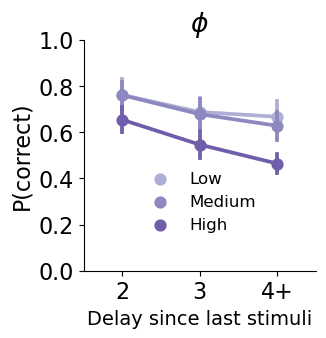

In [9]:
key = "delay_since_last_stimuli"
res = train_df[train_df.delay_since_last_stimuli > 1].copy()
# Create 5 equal-width bins for bias values
res["phi group"] = pd.qcut(res["phi"], q=3, labels=["Low", "Medium", "High"])
res[f"{key}_cat"] = res[key].apply(lambda x: "4+" if x > 4 else str(x))

res = (
    res.groupby(["agentid", f"{key}_cat", "phi group"])[["rewards"]]
    .mean()
    .reset_index()
)

plt.rcParams.update({"font.size": 16})
fig, ax = plt.subplots(1, 1, figsize=(3, 3), sharey=True)
ax = sns.pointplot(
    data=res,
    x=f"{key}_cat",
    y="rewards",
    order=["2", "3", "4+"],
    hue="phi group",
    palette=sns.color_palette("Purples")[2:],
    ax=ax,
    ci=95,
)
ax.set_ylabel("P(correct)")
ax.set_yticks(np.round(np.arange(0, 1.2, 0.2), 2))
ax.set_title(r"$\phi$")
ax.set_xlabel("Delay since last stimuli", fontsize=14)
# sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), fontsize=12)
sns.move_legend(
    ax,
    "lower center",
    bbox_to_anchor=(0.5, 0.1),
    ncol=1,
    fontsize=12,
    markerscale=1,
    frameon=False,
    title=None,
)
sns.despine()
sns.despine()

# Extract input features and output labels

## Preprocess features

In [8]:
from utils.feature_utils import (
    get_iter_acc_without_switches,
    get_iter_acc_with_switches,
    extract_features_blockless,
)

# Extract features in RL based models. Skip this part if it is not relevant to your task or model.
has_switches = train_df.isswitch.nunique() == 2
if "stim_iter" not in train_df.columns:
    td_iter = (
        get_iter_acc_with_switches(train_df)
        if has_switches
        else get_iter_acc_without_switches(train_df)
    )
td_iter["delay_since_last_stimuli"] = train_df["delay_since_last_stimuli"].to_list()

if has_switches:
    td_iter.loc[td_iter.trials == 0, "isswitch"] = 1
else:
    td_iter["isswitch"] = td_iter["trials"].apply(lambda x: 1 if x == 0 else 0)


td_iter["prev_action"] = (
    train_df.groupby(["agentid", "block_no"])["actions"]
    .shift(1)
    .fillna(-1)
    .astype(int)
    .to_list()
)

sorted_col = ["agentid", "block_no", "stimuli"]
td_iter_order = td_iter.sort_values(sorted_col)

## Split training and validation dataset

In [10]:
val_agent_ids = np.random.choice(
    td_iter_order.agentid.nunique(), int(N_AGENTS * 0.1), replace=False
)
val_data = td_iter_order[td_iter_order.agentid.isin(val_agent_ids)]
training_data = td_iter_order[~td_iter_order.agentid.isin(val_agent_ids)]
N_TRAIN_AGENT = training_data.agentid.nunique()
print(training_data.agentid.nunique(), val_data.agentid.nunique())

90 10


## Extract features

In [11]:
feature_list = [
    "actions",
    "rewards",
    "stim_iter",
    "isswitch",
    "prev_action",
    "delay_since_last_stimuli",
]
train_features = extract_features_blockless(training_data, feature_list, [])
val_features = extract_features_blockless(val_data, feature_list, [])

print("Train features shape:", train_features.shape)
print("Val features shape:", val_features.shape)

Train features shape: (90, 936, 6)
Val features shape: (10, 936, 6)


## Extract and preprocess labels

In [12]:
from utils.feature_utils import (
    get_condition_aware_labels,
    normalize_val_labels,
    normalize_train_labels,
)

targeted_params = ["beta", "alpha", "phi", "stickiness"]
train_labels = get_condition_aware_labels(
    train_df[~train_df.agentid.isin(val_agent_ids)], targeted_params, []
)
val_labels = get_condition_aware_labels(
    train_df[train_df.agentid.isin(val_agent_ids)], targeted_params, []
)

normalized_train_labels, name_to_scaler = normalize_train_labels(train_labels)
normalized_val_labels = normalize_val_labels(val_labels, name_to_scaler)
print(normalized_train_labels.shape, normalized_val_labels.shape)

(90, 4) (10, 4)


/Users/ccnlab/Development/dl4rl/utils/feature_utils.py:130: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  unique_values = grouped.apply(
/Users/ccnlab/Development/dl4rl/utils/feature_utils.py:130: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  unique_values = grouped.apply(


## Shuffle dataset

In [ ]:
from sklearn.utils import shuffle

train_features, normalized_train_labels = shuffle(
    train_features, normalized_train_labels, random_state=0
)
val_features, normalized_val_labels = shuffle(
    val_features, normalized_val_labels, random_state=0
)
print(train_features.shape, val_features.shape, normalized_val_labels.shape)

(90, 936, 6) (10, 936, 6) (10, 4)


# Train a neural estimator

In [ ]:
### CHANGE ME
# this is a small network for demonstration purpose
# you can change the network architecture to your own needs
batch_size = 32
units = 32
dropout = 0.065
dropout1 = 0.1929
dropout2 = 0.113
learning_rate = 0.3
###

tf.keras.utils.set_random_seed(11)
identifier = (
    f"rlf_B{batch_size}_U{units}_D{dropout}_D{dropout1}_D{dropout2}_{learning_rate}"
)
param_settings = {
    "feature_dim": train_features.shape[-1],
    "output_dims": normalized_train_labels.shape[-1],
    "units": units,
    "dropout": dropout,
    "dropout1": dropout1,
    "dropout2": dropout2,
    "learning_rate": learning_rate,
}
best_model = get_model_for_parameter_estimation(param_settings)

print(identifier)

rlf_B32_U32_D0.065_D0.1929_D0.113_0.3


In [41]:
callbacks = [EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)]

start = time.time()
history = best_model.fit(
    train_features,
    normalized_train_labels,
    epochs=10, # CHANGE ME to higher number e.g., 600
    batch_size=batch_size,
    callbacks=callbacks,
    validation_data=(val_features, normalized_val_labels),
    verbose=2,
)

end = time.time()

Epoch 1/10


2026-11-01 11:07:55.837742: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


3/3 - 3s - 838ms/step - loss: 1.5791 - val_loss: 1.2846
Epoch 2/10
3/3 - 0s - 150ms/step - loss: 1.0859 - val_loss: 1.0268
Epoch 3/10
3/3 - 0s - 145ms/step - loss: 1.0339 - val_loss: 0.9212
Epoch 4/10
3/3 - 0s - 146ms/step - loss: 1.0425 - val_loss: 0.9005
Epoch 5/10
3/3 - 0s - 146ms/step - loss: 1.0128 - val_loss: 0.9573
Epoch 6/10
3/3 - 0s - 147ms/step - loss: 1.0119 - val_loss: 1.0202
Epoch 7/10
3/3 - 0s - 146ms/step - loss: 1.0222 - val_loss: 1.0115
Epoch 8/10
3/3 - 0s - 150ms/step - loss: 1.0141 - val_loss: 0.9656
Epoch 9/10
3/3 - 0s - 146ms/step - loss: 1.0048 - val_loss: 0.9400
Epoch 10/10
3/3 - 0s - 149ms/step - loss: 1.0045 - val_loss: 0.9453


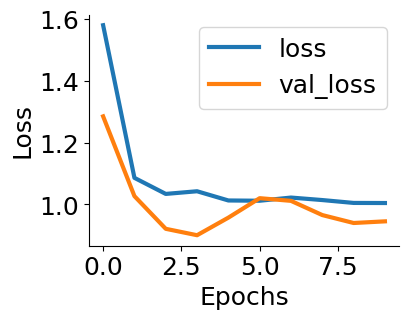

In [51]:
result = pd.DataFrame(history.history)

plt.rcParams.update({'font.size': 18})
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(4, 3))
ax.plot(result.index, result["loss"], linewidth=3, label="loss")
ax.plot(result.index, result["val_loss"], linewidth=3, label="val_loss")
ax.legend()
ax.set_xlabel('Epochs')
ax.set_ylabel('Loss')
sns.despine()

# Evaludate neural estimators

## Generate test dataset

In [5]:
N_TEST_AGENTS = 100  # number of agents - change to your own needs

parameters_dist = generate_rlf_parameters(N_TEST_AGENTS)
with ProcessPoolExecutor(max_workers=2) as executor:
    futures = [
        executor.submit(
            simulate_agent,
            a,
            pval,
            num_blocks,
            [num_stim, num_stim],
            min_switches,
            iter_per_stimuli,
            num_actions,
            all_seq[a % len(all_seq)],
            params_dist=parameters_dist[a],
        )
        for a in range(N_TEST_AGENTS)
    ]
    test_data_list = [future.result() for future in tqdm.tqdm(futures)]

test_df = pd.concat(test_data_list)

test_df.head(3)

100%|██████████| 100/100 [00:03<00:00, 26.05it/s]


,actions,stimuli,correct_actions,rewards,trials,isswitch,iscorrectaction,rpe_history,alpha,neg_alpha,bias,beta,phi,stickiness,agentid,eps,delay_since_last_stimuli,block_no,condition,set_size
0,1,0,2,0,0,0,0,-0.333333,0.799939,0.799939,1,12.140239,0.054321,-0.978706,0,0,0,0,1,6
1,2,1,0,0,1,0,0,-0.333333,0.799939,0.799939,1,12.140239,0.054321,-0.978706,0,0,0,0,1,6
2,0,2,0,1,2,0,1,0.666667,0.799939,0.799939,1,12.140239,0.054321,-0.978706,0,0,0,0,1,6


## Extract test features

In [13]:
if "stim_iter" not in test_df.columns:
    test_iter = (
        get_iter_acc_with_switches(test_df)
        if has_switches
        else get_iter_acc_without_switches(test_df)
    )
test_iter["delay_since_last_stimuli"] = test_df["delay_since_last_stimuli"].to_list()

if has_switches:
    test_iter.loc[test_iter.trials == 0, "isswitch"] = 1
else:
    test_iter["isswitch"] = test_iter["trials"].apply(lambda x: 1 if x == 0 else 0)


test_iter["prev_action"] = (
    test_df.groupby(["agentid", "block_no"])["actions"]
    .shift(1)
    .fillna(-1)
    .astype(int)
    .to_list()
)

test_iter_order = test_iter.sort_values(sorted_col)
test_features = extract_features_blockless(test_iter_order, feature_list, [])
true_labels = get_condition_aware_labels(test_df, targeted_params, [])

/Users/ccnlab/Development/dl4rl/utils/feature_utils.py:130: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  unique_values = grouped.apply(


## Inference

In [14]:
# LOAD trained model for RLF parameter estimation
model_name = "9000a_12b_78t_rlf_B128_U96_D0.065_D0.1929_D0.113_0.002_model.keras" 
gru_model = tf.keras.models.load_model(f"./models/{model_name}", compile=True)

In [15]:
from utils.feature_utils import (
    get_recovered_parameters,
)

beta_multiplier = 20
predicted = gru_model.predict(test_features)
result = get_recovered_parameters(name_to_scaler, true_labels, predicted)
if ("true_beta" in result.columns) and (result.true_beta.max() > 1):
    result["true_beta"] = result["true_beta"] / beta_multiplier
    result["dl_beta"] = result["dl_beta"] / beta_multiplier

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step

2026-11-02 13:28:49.652112: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step


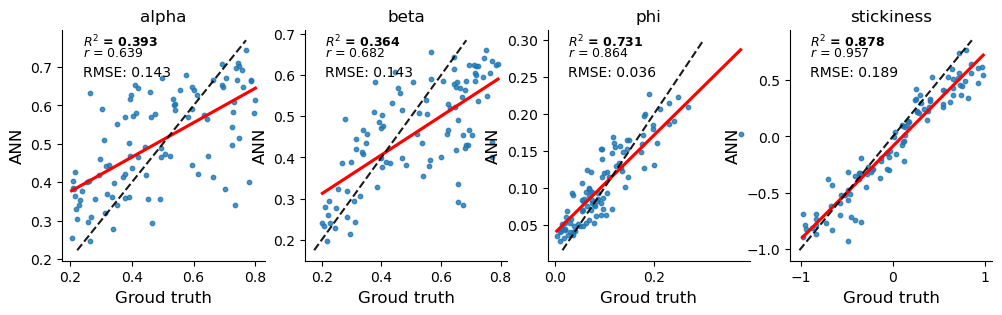

In [16]:
from utils.evaluation_utils import (
    add_corr_scores,
)
from sklearn.metrics import root_mean_squared_error

params = list(true_labels.keys())
n_row, n_col = 1, len(params)
f, axarr = plt.subplots(n_row, n_col, figsize=(3 * n_col, 3 * n_row))

for i, p in enumerate(np.sort(params)):
    true_l, dl_l = f"true_{p}", f"dl_{p}"

    ax = sns.regplot(
        data=result,
        ci=None,
        x=true_l,
        y=dl_l,
        ax=axarr.flat[i],
        scatter_kws=dict(s=10),
        line_kws=dict(color="r"),
    )
    ax = add_corr_scores(ax, result[true_l], result[dl_l])

    ax.plot(
        [ax.get_ylim()[0], ax.get_ylim()[1]],
        [ax.get_ylim()[0], ax.get_ylim()[1]],
        color="black",
        alpha=0.9,
        linestyle="dashed",
    )

    mse = root_mean_squared_error(result[true_l], result[dl_l])
    ax.text(0.1, 0.8, f"RMSE: {mse:.3f}", transform=ax.transAxes, fontsize=10)

    ax.set_title(p, fontsize=12)
    ax.set_xlabel("Groud truth", fontsize=12)
    ax.set_ylabel("ANN", fontsize=12)

sns.despine()

## Permutation tests

In [17]:
from utils.feature_importance_utils import (
    permutation_importance_global_sequence,
)

test_labels, _ = normalize_train_labels(true_labels)  

ranking = permutation_importance_global_sequence(
    model=gru_model,
    X_val=test_features,
    y_val=test_labels,
    feature_names=feature_list,
    n_repeats=3,
    batch_size=64,
    shuffle_mode="within_sample",
    block_size=32,
    random_state=123
)

2026-11-02 13:30:49.784872: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Baseline loss: 0.37671783566474915
Permutation feature actions
Permutation loss: 1.3904324769973755
Permutation loss: 1.3753373622894287
Permutation loss: 1.3654366731643677
Permutation feature rewards
Permutation loss: 1.5062379837036133
Permutation loss: 1.5253793001174927
Permutation loss: 1.5402331352233887
Permutation feature stim_iter
Permutation loss: 1.0230449438095093
Permutation loss: 1.0469393730163574
Permutation loss: 0.9959163069725037
Permutation feature isswitch
Permutation loss: 0.39851582050323486
Permutation loss: 0.40378448367118835
Permutation loss: 0.4003816843032837
Permutation feature prev_action
Permutation loss: 1.239725947380066
Permutation loss: 1.2297443151474
Permutation loss: 1.2170485258102417
Permutation feature delay_since_last_stimuli
Permutation loss: 0.8521095514297485
Permutation loss: 0.8489726185798645
Permutation loss: 0.862365186214447


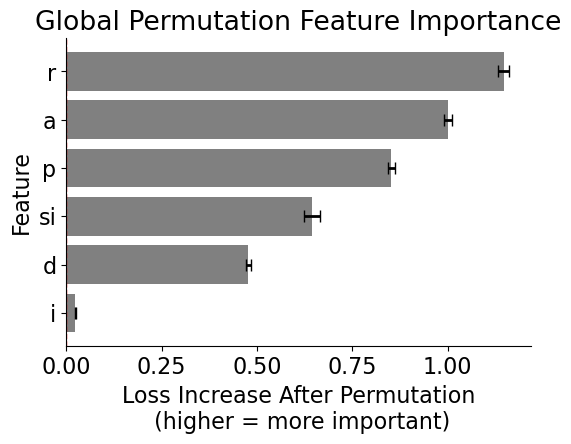

In [18]:
plt.rcParams.update({"font.size": 16})
fig, ax = plt.subplots(figsize=(6, 4))
ax = sns.barplot(
    data=ranking,
    x="importance_mean",
    y="feature",
    ax=ax,
    color="grey",
)
# add error bars if present
if "importance_std" in ranking.columns:
    ax.errorbar(
        x=ranking["importance_mean"],
        y=range(len(ranking)),
        xerr=ranking["importance_std"],
        fmt="none",
        ecolor="black",
        capsize=4,
        lw=2
    )
ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.set_title("Global Permutation Feature Importance")# (missing %d%% data)" % k)

short_labels = ['si' if l.get_text() == 'stim_iter' else l.get_text()[:1] for l in ax.get_yticklabels()]
ax.set_yticklabels(short_labels, rotation=0)
ax.set_xlabel("Loss Increase After Permutation\n (higher = more important)")
ax.set_ylabel("Feature")
sns.despine(ax=ax)